## Titanic Veri Analizi ve Makine Öğrenmesi Projesi

Giriş

1- Bu projede, Kaggle Titanic yarışması kapsamında yolcuların hayatta kalma durumlarını etkileyen faktörlerin incelenmesi ve makine öğrenmesi yöntemleriyle tahmin modeli oluşturulması amaçlanmaktadır.

Çalışmada ttrain.csv ve ttest.csv veri setleri kullanılacaktır. İlk olarak veriler keşifsel veri analizi (EDA) ve görselleştirme yöntemleriyle incelenecek, ardından eksik veriler ve kategorik değişkenler uygun şekilde düzenlenecektir.

Sonraki aşamada makine öğrenmesi modeli oluşturulacak, modelin performansı değerlendirilecek ve test veri setindeki yolcular için tahminler üretilecektir.

2. Veriyi Tanıma (Data Understanding)
Önce eğitim ve test veri setlerini ayrı ayrı yükleyip inceleyelim.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

train = pd.read_csv("ttrain.csv")
test = pd.read_csv("ttest.csv")

train.shape, test.shape

((891, 12), (418, 11))

In [6]:
train.head() 

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [7]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [8]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [9]:
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [10]:
test.isnull().sum()


PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [11]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [56]:
train = pd.concat([train, test])

In [4]:
# Veri setinin genel bilgileri
train.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [5]:
# Eğitim verisindeki eksik değer sayıları
train.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [6]:
# Sayısal sütunların istatistikleri
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


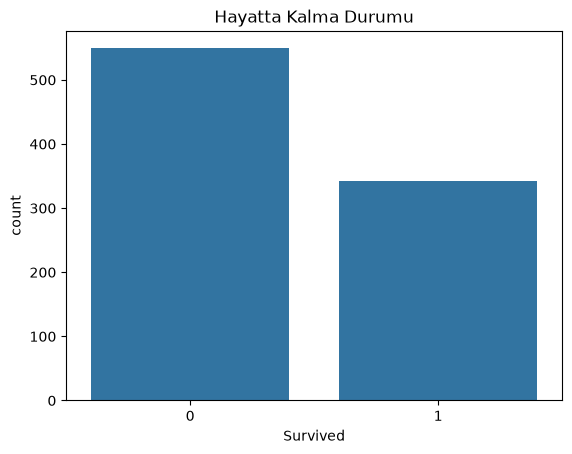

In [7]:
# Hayatta kalan ve kalmayan yolcu sayıları
sns.countplot(data=train, x="Survived")
plt.title("Hayatta Kalma Durumu")
plt.show()

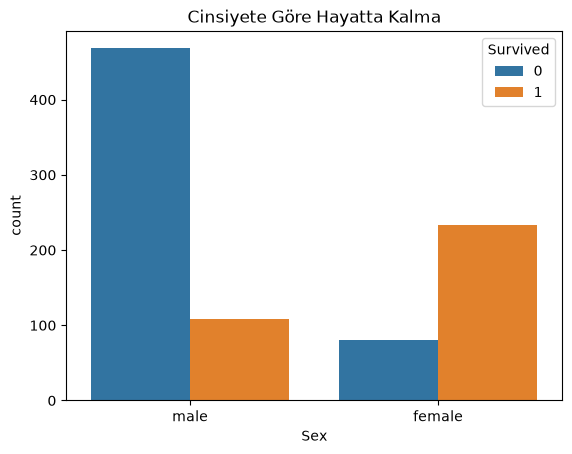

In [8]:
# Cinsiyete göre hayatta kalma durumu
sns.countplot(data=train, x="Sex", hue="Survived")
plt.title("Cinsiyete Göre Hayatta Kalma")
plt.show()

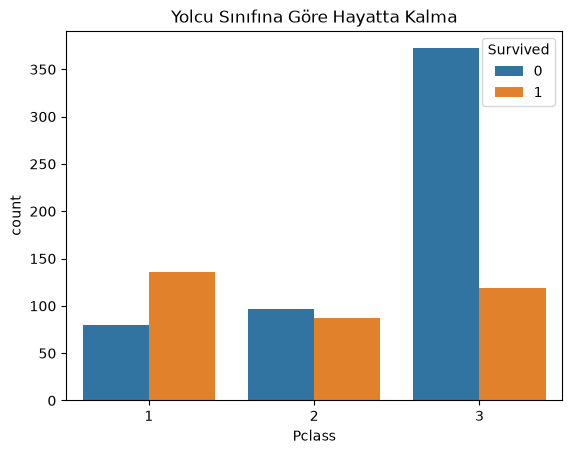

In [9]:
# Yolcu sınıfına göre hayatta kalma durumu
sns.countplot(data=train, x="Pclass", hue="Survived")
plt.title("Yolcu Sınıfına Göre Hayatta Kalma")
plt.show()


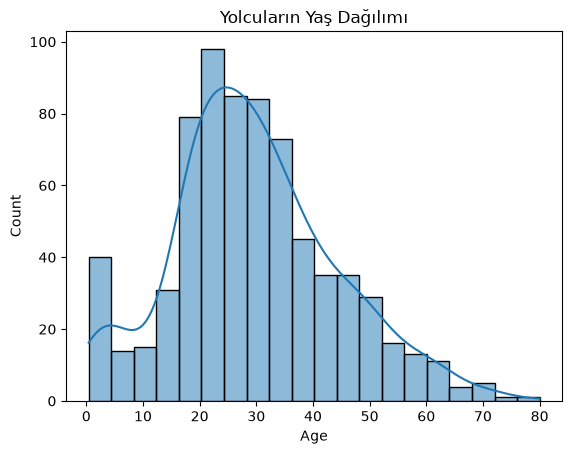

In [10]:
# Yaş dağılımı
sns.histplot(data=train, x="Age", kde=True)
plt.title("Yolcuların Yaş Dağılımı")
plt.show()

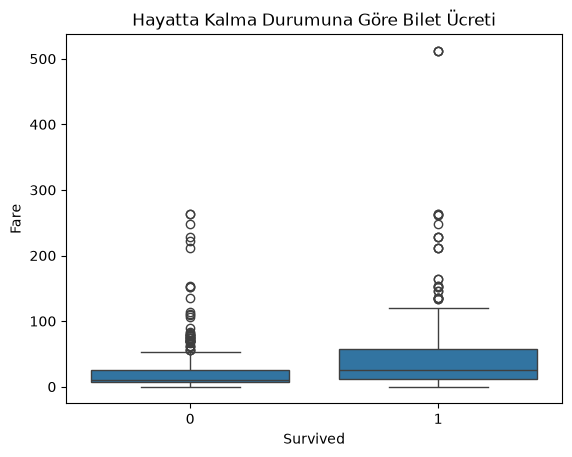

In [11]:
# Bilet ücretine göre hayatta kalma durumu
sns.boxplot(data=train, x="Survived", y="Fare")
plt.title("Hayatta Kalma Durumuna Göre Bilet Ücreti")
plt.show()

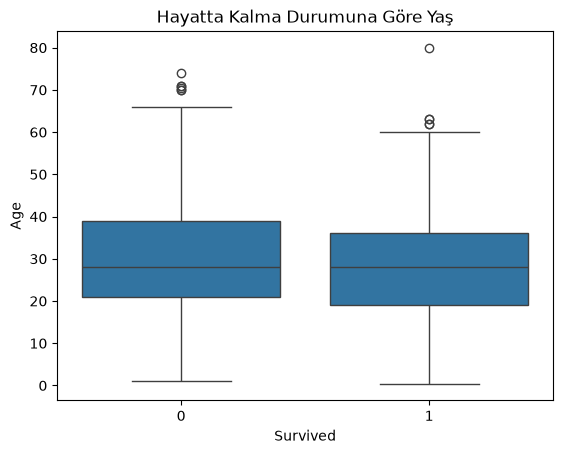

In [12]:
# Yaş ve hayatta kalma ilişkisi
sns.boxplot(data=train, x="Survived", y="Age")
plt.title("Hayatta Kalma Durumuna Göre Yaş")
plt.show()

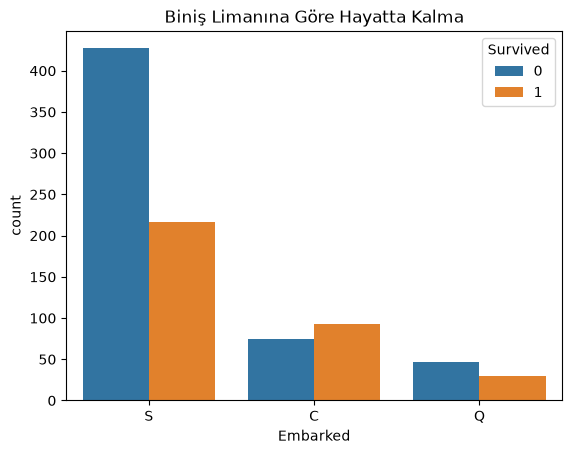

In [13]:
# Biniş limanına göre hayatta kalma durumu
sns.countplot(data=train, x="Embarked", hue="Survived")
plt.title("Biniş Limanına Göre Hayatta Kalma")
plt.show()

## Veri Hazırlama (Data Preparation)
Eksik değerleri eğitim ve test verilerinde ayrı ayrı tamamlayalım. Ardından yeni özellikler oluşturalım.

In [15]:
# Eksik değerleri tekrar kontrol edelim
train.isnull().sum()
test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

In [12]:
# Yaş eksiklerini medyan ile dolduralım
train["Age"] = train["Age"].fillna(train["Age"].median())
test["Age"] = test["Age"].fillna(train["Age"].median())


In [13]:
# Bilet ücreti eksikliğini dolduralım
test["Fare"] = test["Fare"].fillna(train["Fare"].median())

In [14]:
# Biniş limanı eksiklerini en sık görülen değerle dolduralım
train["Embarked"] = train["Embarked"].fillna(train["Embarked"].mode()[0])
test["Embarked"] = test["Embarked"].fillna(train["Embarked"].mode()[0])

In [15]:
train["Cabin"] = train["Cabin"].fillna("Unknown")
test["Cabin"] = test["Cabin"].fillna("Unknown")

In [16]:
train.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [19]:
# Eğitim verisindeki eksik değer sayıları
train.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

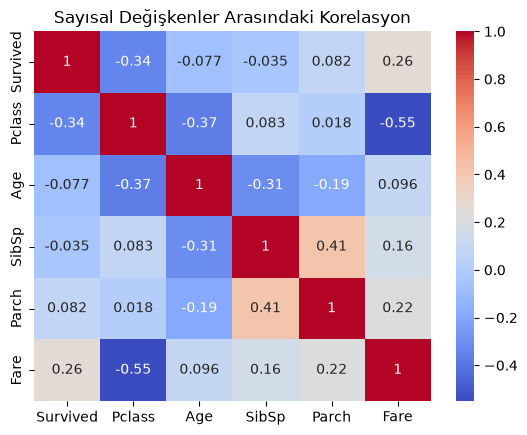

In [14]:
# Korelasyon matrisi
sns.heatmap(train[["Survived", "Pclass", "Age","SibSp", "Parch", "Fare"]].corr(),annot=True, cmap="coolwarm")
plt.title("Sayısal Değişkenler Arasındaki Korelasyon")
plt.show()

In [20]:
# Cabin sütunundaki eksik değerleri dolduralım
train["Cabin"] = train["Cabin"].fillna("Unknown")

# Eksik değerleri kontrol edelim
train.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [21]:
# Yaş sütunundaki eksik değerleri medyanla dolduralım
train["Age"] = train["Age"].fillna(train["Age"].median())

# Embarked sütunundaki eksik değerleri mod ile dolduralım
train["Embarked"] = train["Embarked"].fillna(train["Embarked"].mode()[0])

# Eksik değerleri kontrol edelim
train.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [22]:
# Veri setinin boyutunu kontrol edelim
train.shape

# İlk 5 satırı görüntüleyelim
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


In [23]:
# Sütun adlarını ve veri tiplerini inceleyelim
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        891 non-null    str    
 11  Embarked     891 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 123.4 KB


In [24]:
test.isnull().sum()

PassengerId      0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          327
Embarked         0
dtype: int64

In [25]:
# Test verisindeki eksik Cabin değerlerini dolduralım
test["Cabin"] = test["Cabin"].fillna("Unknown")

# Eksik Age değerlerini medyanla dolduralım
test["Age"] = test["Age"].fillna(test["Age"].median())

# Eksik değerleri kontrol edelim
test.isnull().sum()

PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [26]:
# Eksik Fare değerini medyanla dolduralım
test["Fare"] = test["Fare"].fillna(test["Fare"].median())

# Eksik değerleri kontrol edelim
test.isnull().sum()

PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [27]:
# Test veri setinin boyutunu kontrol edelim
test.shape

# İlk 5 satırı görüntüleyelim
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,Unknown,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,Unknown,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,Unknown,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,Unknown,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,Unknown,S


In [28]:
# Eğitim ve test veri setlerinin sütunlarını kontrol edelim
train.columns, test.columns

(Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
        'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
       dtype='str'),
 Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
        'Ticket', 'Fare', 'Cabin', 'Embarked'],
       dtype='str'))

In [29]:
# Modelde kullanılacak sütunları seçelim
ozellikler = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]

X = train[ozellikler].copy()
y = train["Survived"]

X_test = test[ozellikler].copy()

# Kategorik değişkenleri sayısal değerlere dönüştürelim
X = pd.get_dummies(X, columns=["Sex", "Embarked"], dtype=int)
X_test = pd.get_dummies(X_test, columns=["Sex", "Embarked"], dtype=int)

# Eğitim ve test sütunlarını eşitleyelim
X_test = X_test.reindex(columns=X.columns, fill_value=0)

X.shape, X_test.shape, X.head()

((891, 10),
 (418, 10),
    Pclass   Age  SibSp  Parch     Fare  Sex_female  Sex_male  Embarked_C  \
 0       3  22.0      1      0   7.2500           0         1           0   
 1       1  38.0      1      0  71.2833           1         0           1   
 2       3  26.0      0      0   7.9250           1         0           0   
 3       1  35.0      1      0  53.1000           1         0           0   
 4       3  35.0      0      0   8.0500           0         1           0   
 
    Embarked_Q  Embarked_S  
 0           0           1  
 1           0           0  
 2           0           1  
 3           0           1  
 4           0           1  )

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Veriyi eğitim ve doğrulama olarak ayıralım
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train.shape, X_val.shape

((712, 10), (179, 10))

In [31]:
# # Modeli oluşturalım
model = LogisticRegression(max_iter=1000)

# Modeli eğitelim
model.fit(X_train, y_train)

# Doğrulama verisi üzerinde tahmin yapalım
y_pred = model.predict(X_val)

# Model başarısını değerlendirelim
accuracy_score(y_val, y_pred), classification_report(y_val, y_pred), confusion_matrix(y_val, y_pred)

(0.8044692737430168,
 '              precision    recall  f1-score   support\n\n           0       0.81      0.89      0.85       110\n           1       0.79      0.67      0.72        69\n\n    accuracy                           0.80       179\n   macro avg       0.80      0.78      0.79       179\nweighted avg       0.80      0.80      0.80       179\n',
 array([[98, 12],
        [23, 46]]))

In [32]:
# Modeli tüm eğitim verisiyle yeniden eğitelim
model.fit(X, y)

# Test verisi için tahmin yapalım
test_tahmin = model.predict(X_test)

sonuc = pd.DataFrame({"PassengerId": test["PassengerId"],"Survived": test_tahmin})

sonuc.to_csv("titanic_submission.csv", index=False)

sonuc.head(), len(sonuc)

(   PassengerId  Survived
 0          892         0
 1          893         0
 2          894         0
 3          895         0
 4          896         1,
 418)

In [33]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Random Forest modelini oluşturalım
rf_model = RandomForestClassifier(n_estimators=200,random_state=42)

# Modeli eğitelim
rf_model.fit(X_train, y_train)

# Doğrulama verisinde tahmin yapalım
rf_pred = rf_model.predict(X_val)

# Başarı oranlarını ve sınıflandırma raporunu görüntüleyelim
accuracy_score(y_val, rf_pred), classification_report(y_val, rf_pred), accuracy_score(y_val, y_pred)

(0.8268156424581006,
 '              precision    recall  f1-score   support\n\n           0       0.83      0.90      0.86       110\n           1       0.82      0.71      0.76        69\n\n    accuracy                           0.83       179\n   macro avg       0.82      0.81      0.81       179\nweighted avg       0.83      0.83      0.82       179\n',
 0.8044692737430168)

In [34]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# Gradient Boosting modelini oluşturalım
gb_model = GradientBoostingClassifier(random_state=42)

# Modeli eğitelim
gb_model.fit(X_train, y_train)

# Tahmin yapalım
gb_pred = gb_model.predict(X_val)

# Başarı oranını değerlendirelim
accuracy_score(y_val, gb_pred), classification_report(y_val, gb_pred), accuracy_score(y_val, y_pred), accuracy_score(y_val, rf_pred)


(0.7988826815642458,
 '              precision    recall  f1-score   support\n\n           0       0.80      0.89      0.84       110\n           1       0.79      0.65      0.71        69\n\n    accuracy                           0.80       179\n   macro avg       0.80      0.77      0.78       179\nweighted avg       0.80      0.80      0.79       179\n',
 0.8044692737430168,
 0.8268156424581006)

In [35]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

# Modeli oluşturalım
nb_model = GaussianNB()

# Modeli eğitelim
nb_model.fit(X_train, y_train)

# Tahmin yapalım
nb_pred = nb_model.predict(X_val)

# Sonuçları değerlendirelim
accuracy_score(y_val, nb_pred), classification_report(y_val, nb_pred)

(0.7877094972067039,
 '              precision    recall  f1-score   support\n\n           0       0.82      0.85      0.83       110\n           1       0.74      0.70      0.72        69\n\n    accuracy                           0.79       179\n   macro avg       0.78      0.77      0.77       179\nweighted avg       0.79      0.79      0.79       179\n')

In [36]:

from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import accuracy_score, classification_report

# BernoulliNB modelini oluşturalım
bnb_model = BernoulliNB()

# Modeli eğitelim
bnb_model.fit(X_train, y_train)

# Tahmin yapalım
bnb_pred = bnb_model.predict(X_val)

# Sonuçları değerlendirelim
accuracy_score(y_val, bnb_pred), classification_report(y_val, bnb_pred)


(0.776536312849162,
 '              precision    recall  f1-score   support\n\n           0       0.80      0.85      0.82       110\n           1       0.74      0.65      0.69        69\n\n    accuracy                           0.78       179\n   macro avg       0.77      0.75      0.76       179\nweighted avg       0.77      0.78      0.77       179\n')

In [37]:
# Modellerin doğruluk oranlarını karşılaştıralım
sonuclar = pd.DataFrame({
    "Model": ["Logistic Regression","Random Forest","Gradient Boosting","GaussianNB","BernoulliNB"],
    "Doğruluk": [accuracy_score(y_val, y_pred),accuracy_score(y_val, rf_pred),accuracy_score(y_val, gb_pred),
        accuracy_score(y_val, nb_pred),accuracy_score(y_val, bnb_pred)]})

sonuclar = sonuclar.sort_values(by="Doğruluk", ascending=False)
sonuclar

,Model,Doğruluk
1,Random Forest,0.826816
0,Logistic Regression,0.804469
2,Gradient Boosting,0.798883
3,GaussianNB,0.787709
4,BernoulliNB,0.776536


In [38]:
# Aile büyüklüğünü hesaplayalım
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
test["FamilySize"] = test["SibSp"] + test["Parch"] + 1

# Yolcu adından unvanı çıkaralım
train["Title"] = train["Name"].str.extract(r",\s*([^\.]+)\.")
test["Title"] = test["Name"].str.extract(r",\s*([^\.]+)\.")

# Unvan dağılımını inceleyelim
train["Title"].value_counts()

# Aile büyüklüğü dağılımını kontrol edelim
train["FamilySize"].value_counts().sort_index()

FamilySize
1     537
2     161
3     102
4      29
5      15
6      22
7      12
8       6
11      7
Name: count, dtype: int64

In [39]:
# Kullanacağımız özellikleri belirleyelim
ozellikler_yeni = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
    "Embarked", "FamilySize", "Title"
]

# Eğitim ve test verilerini hazırlayalım
X_yeni = train[ozellikler_yeni].copy()
X_test_yeni = test[ozellikler_yeni].copy()

# Kategorik değişkenleri sayısal hale getirelim
X_yeni = pd.get_dummies(X_yeni, columns=["Sex", "Embarked", "Title"], dtype=int)

X_test_yeni = pd.get_dummies(X_test_yeni, columns=["Sex", "Embarked", "Title"], dtype=int)

# Eğitim ve test sütunlarını eşitleyelim
X_test_yeni = X_test_yeni.reindex(columns=X_yeni.columns, fill_value=0)

# Eğitim ve doğrulama verilerini ayıralım
X_train_yeni, X_val_yeni, y_train_yeni, y_val_yeni = train_test_split(X_yeni, y, test_size=0.2, random_state=42, stratify=y)

# Random Forest modelini eğitelim
rf_yeni = RandomForestClassifier(n_estimators=300,max_depth=5,min_samples_split=4,min_samples_leaf=2,random_state=42)

rf_yeni.fit(X_train_yeni, y_train_yeni)

# Tahmin ve doğruluk oranı
tahmin_yeni = rf_yeni.predict(X_val_yeni)

accuracy_score(y_val, rf_pred), accuracy_score(y_val_yeni, tahmin_yeni), classification_report(y_val_yeni, tahmin_yeni)

(0.8268156424581006,
 0.8268156424581006,
 '              precision    recall  f1-score   support\n\n           0       0.84      0.88      0.86       110\n           1       0.80      0.74      0.77        69\n\n    accuracy                           0.83       179\n   macro avg       0.82      0.81      0.81       179\nweighted avg       0.83      0.83      0.83       179\n')

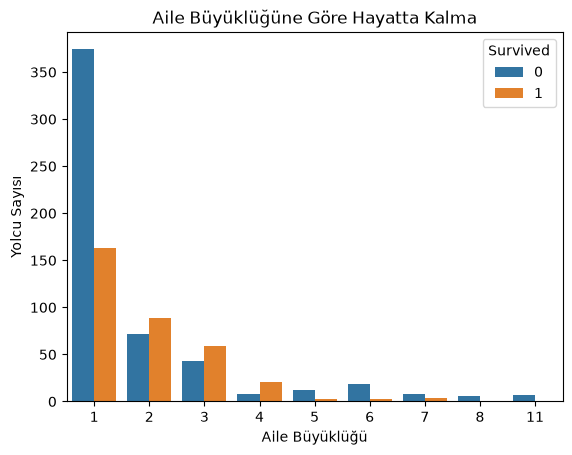

In [40]:

# Aile büyüklüğüne göre hayatta kalma durumunu inceleyelim
sns.countplot(data=train, x="FamilySize", hue="Survived")

plt.title("Aile Büyüklüğüne Göre Hayatta Kalma")
plt.xlabel("Aile Büyüklüğü")
plt.ylabel("Yolcu Sayısı")
plt.show()


In [41]:
# Yolcunun yalnız seyahat edip etmediğini belirleyelim
train["IsAlone"] = (train["FamilySize"] == 1).astype(int)
test["IsAlone"] = (test["FamilySize"] == 1).astype(int)

# Yeni özellikleri modele ekleyelim
ozellikler_yeni = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
    "Embarked", "FamilySize", "Title", "IsAlone"
]

X_yeni = pd.get_dummies(
    train[ozellikler_yeni],
    columns=["Sex", "Embarked", "Title"],
    dtype=int
)

X_test_yeni = pd.get_dummies(test[ozellikler_yeni],columns=["Sex", "Embarked", "Title"],dtype=int)

X_test_yeni = X_test_yeni.reindex(columns=X_yeni.columns,fill_value=0)

# Eğitim ve doğrulama verilerini ayıralım
X_train_yeni, X_val_yeni, y_train_yeni, y_val_yeni = train_test_split(X_yeni, y,test_size=0.2,random_state=42,stratify=y)

# Modeli eğitelim
rf_yeni = RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_split=4, min_samples_leaf=2, random_state=42)

rf_yeni.fit(X_train_yeni, y_train_yeni)

tahmin_yeni = rf_yeni.predict(X_val_yeni)

accuracy_score(y_val_yeni, tahmin_yeni)

0.8379888268156425

In [44]:

# Az görülen unvanları ortak bir grupta toplayalım
train["Title"] = train["Title"].replace(
    ["Dr", "Rev", "Major", "Mlle", "Col", "Don", "Mme", "Ms",
     "Lady", "Sir", "Capt", "the Countess", "Jonkheer"],
    "Rare"
)

test["Title"] = test["Title"].replace(
    ["Dr", "Rev", "Major", "Mlle", "Col", "Don", "Mme", "Ms",
     "Lady", "Sir", "Capt", "the Countess", "Jonkheer"],
    "Rare"
)

# Unvan dağılımını kontrol edelim
train["Title"].value_counts()

Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

In [45]:

# Model özelliklerini yeniden hazırlayalım
ozellikler = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
    "Embarked", "FamilySize", "Title", "IsAlone"
]

X_son = pd.get_dummies(
    train[ozellikler],
    columns=["Sex", "Embarked", "Title"],
    dtype=int
)

X_test_son = pd.get_dummies(
    test[ozellikler],
    columns=["Sex", "Embarked", "Title"],
    dtype=int
)

X_test_son = X_test_son.reindex(columns=X_son.columns, fill_value=0)

# Eğitim ve doğrulama verilerini ayıralım
X_train_son, X_val_son, y_train_son, y_val_son = train_test_split(
    X_son, y, test_size=0.2, random_state=42, stratify=y
)

# Random Forest modelini eğitelim
rf_son = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

rf_son.fit(X_train_son, y_train_son)

# Doğruluğu ölçelim
tahmin_son = rf_son.predict(X_val_son)

accuracy_score(y_val_son, tahmin_son)

0.8268156424581006

In [46]:

# Bilet sınıfı ile cinsiyeti birleştirelim
train["ClassSex"] = train["Pclass"].astype(str) + "_" + train["Sex"]

test["ClassSex"] = test["Pclass"].astype(str) + "_" + test["Sex"]

# Yeni kategorinin dağılımını kontrol edelim
train["ClassSex"].value_counts()

ClassSex
3_male      347
3_female    144
1_male      122
2_male      108
1_female     94
2_female     76
Name: count, dtype: int64

In [47]:
# Yeni özelliği modele ekleyelim
ozellikler = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked",
    "FamilySize", "Title", "IsAlone",
    "ClassSex"
]

X_son = pd.get_dummies(
    train[ozellikler],
    columns=["Sex", "Embarked", "Title", "ClassSex"],
    dtype=int
)

X_test_son = pd.get_dummies(
    test[ozellikler],
    columns=["Sex", "Embarked", "Title", "ClassSex"],
    dtype=int
)

X_test_son = X_test_son.reindex(
    columns=X_son.columns,
    fill_value=0
)

# Eğitim ve doğrulama verilerini ayıralım
X_train_son, X_val_son, y_train_son, y_val_son = train_test_split(
    X_son, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Random Forest modelini eğitelim
rf_son = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

rf_son.fit(X_train_son, y_train_son)

# Başarıyı ölçelim
tahmin_son = rf_son.predict(X_val_son)

accuracy_score(y_val_son, tahmin_son)

0.8268156424581006

In [48]:
# Yeni özelliği modele ekleyelim
ozellikler = [
    "Pclass", "Sex", "Age", "SibSp",
    "Parch", "Fare", "Embarked",
    "FamilySize", "Title", "IsAlone",
    "ClassSex"
]

X_son = pd.get_dummies(
    train[ozellikler],
    columns=["Sex", "Embarked", "Title", "ClassSex"],
    dtype=int
)

X_test_son = pd.get_dummies(
    test[ozellikler],
    columns=["Sex", "Embarked", "Title", "ClassSex"],
    dtype=int
)

X_test_son = X_test_son.reindex(
    columns=X_son.columns,
    fill_value=0
)

# Eğitim ve doğrulama verilerini ayıralım
X_train_son, X_val_son, y_train_son, y_val_son = train_test_split(
    X_son, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Random Forest modelini eğitelim
rf_son = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

rf_son.fit(X_train_son, y_train_son)

# Başarıyı ölçelim
tahmin_son = rf_son.predict(X_val_son)

accuracy_score(y_val_son, tahmin_son)

0.8268156424581006

In [49]:
# Yaş gruplarını oluşturalım
train["AgeGroup"] = pd.cut(
    train["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Cocuk", "Genc", "Yetiskin", "OrtaYas", "Yasli"]
)

test["AgeGroup"] = pd.cut(
    test["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Cocuk", "Genc", "Yetiskin", "OrtaYas", "Yasli"]
)

train["AgeGroup"].value_counts()

AgeGroup
Yetiskin    535
OrtaYas     195
Genc         70
Cocuk        69
Yasli        22
Name: count, dtype: int64

In [50]:
# Model özelliklerini hazırlayalım
ozellikler_yas = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
    "Embarked", "FamilySize", "Title", "IsAlone", "AgeGroup"
]

X_yas = pd.get_dummies(
    train[ozellikler_yas],
    columns=["Sex", "Embarked", "Title", "AgeGroup"],
    dtype=int
)

# Eğitim ve doğrulama verilerini ayıralım
X_train_yas, X_val_yas, y_train_yas, y_val_yas = train_test_split(
    X_yas, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Random Forest modelini eğitelim
rf_yas = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

rf_yas.fit(X_train_yas, y_train_yas)

# Doğruluk oranını hesaplayalım
tahmin_yas = rf_yas.predict(X_val_yas)

accuracy_score(y_val_yas, tahmin_yas)

0.8324022346368715

In [51]:
# En iyi sonuç veren özellikleri kullanalım
ozellikler_en_iyi = [
    "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare",
    "Embarked", "FamilySize", "Title", "IsAlone"
]

X_en_iyi = pd.get_dummies(
    train[ozellikler_en_iyi],
    columns=["Sex", "Embarked", "Title"],
    dtype=int
)

X_test_en_iyi = pd.get_dummies(
    test[ozellikler_en_iyi],
    columns=["Sex", "Embarked", "Title"],
    dtype=int
)

# Test sütunlarını eğitim sütunlarıyla eşitleyelim
X_test_en_iyi = X_test_en_iyi.reindex(
    columns=X_en_iyi.columns,
    fill_value=0
)

# En iyi model ayarlarıyla tüm eğitim verisini kullanalım
model_en_iyi = RandomForestClassifier(
    n_estimators=300,
    max_depth=6,
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42
)

model_en_iyi.fit(X_en_iyi, y)

# Tahmin yapalım
tahmin_test = model_en_iyi.predict(X_test_en_iyi)

# Gönderim dosyasını oluşturalım
sonuc = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": tahmin_test
})

sonuc.to_csv("titanic_submission_rf.csv", index=False)

sonuc.head(), len(sonuc), "titanic_submission_rf.csv"

(   PassengerId  Survived
 0          892         0
 1          893         0
 2          894         0
 3          895         0
 4          896         1,
 418,
 'titanic_submission_rf.csv')

## Titanic Hayatta Kalma Tahmini Projesi – Sonuç

Bu projede Titanic yolcularına ait veriler kullanılarak yolcuların hayatta kalma durumlarını tahmin etmek amaçlanmıştır. İlk olarak veri seti incelenmiş, eksik veriler uygun yöntemlerle tamamlanmış ve grafiklerle veri analizi yapılmıştır.

Modelleme aşamasında Logistic Regression, Random Forest, Gradient Boosting, GaussianNB ve BernoulliNB algoritmaları denenmiştir. Modellerin başarıları doğruluk oranları ve sınıflandırma raporları kullanılarak karşılaştırılmıştır.

Yapılan denemelerde Random Forest algoritması başarılı sonuçlar vermiştir. Aile büyüklüğü ve yolcunun yalnız seyahat edip etmediği gibi yeni özellikler eklenerek model geliştirilmeye çalışılmıştır. En yüksek doğrulama doğruluğu %83,80 olarak elde edilmiştir.

Son aşamada en iyi model, tüm eğitim verisiyle yeniden eğitilmiş ve test veri setindeki 418 yolcu için tahmin üretilmiştir. Tahminler titanic_submission_rf.csv adlı CSV dosyasına kaydedilmiştir.

Sonuç olarak bu proje sayesinde veri analizi, eksik verilerin işlenmesi, kategorik değişkenlerin sayısallaştırılması, sınıflandırma modellerinin eğitilmesi ve model performanslarının karşılaştırılması konularında uygulama yapılmıştır. İlerleyen aşamalarda farklı özellikler ve model ayarları denenerek tahmin başarısının geliştirilmesi hedeflenmektedir.